# Atelier AI - First LightGBM Ranking Experiment

Fit the planned initial LambdaRank configuration on six historical weeks, stop using validation NDCG@12, and compare complete top-12 lists with the three reference methods. This notebook is the first learned experiment, not completion of the planned six-configuration search.

The V1 evaluation and final LightGBM/PyTorch confirmation outcomes remain outside this experiment. See the [evaluation limitations](../docs/evaluation.md) when interpreting this retrospective local benchmark.

## 1. Inputs and model configuration

Features are numeric historical measurements rather than ordered raw identifiers. Missing unobserved recencies remain missing. Training uses complete informative customer-week groups; evaluation retains every target buyer, including retrieval misses.

| Parameter | Initial value |
|---|---:|
| Objective | LambdaRank |
| Learning rate | 0.05 |
| Maximum iterations | 1,000 |
| Leaves | 31 |
| Maximum depth | 8 |
| Minimum examples per leaf | 100 |
| L2 regularization | 1 |
| Seed | 42 |
| Early-stopping patience | 50 |

The stopping metric uses complete target counts for the ideal NDCG ranking. A buyer with every target absent from candidates scores zero, rather than appearing to have a perfect empty-reference ranking. Customers without target purchases are excluded from this target-based average.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
import atelier_ai
from atelier_ai.temporal_protocol import load_protocol
from atelier_ai.notebook_tools import show_figure

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
protocol = load_protocol(PROJECT_ROOT)

from atelier_ai.workflow import fit_first_ranker
experiment,comparison=fit_first_ranker(PROJECT_ROOT)
display(pd.Series({k:experiment[k] for k in ['best_iteration','fit_seconds','score_seconds','leading_method','mlflow_run_id']}))
display(comparison)

2026/10/25 00:18:05 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds


[25]	valid_0's ndcg_full_reference_at_12: 0.0382923


[50]	valid_0's ndcg_full_reference_at_12: 0.0372471


Early stopping, best iteration is:
[16]	valid_0's ndcg_full_reference_at_12: 0.0389337
Evaluated only: ndcg_full_reference_at_12


2026/10/25 00:18:42 INFO mlflow.tracking.fluent: Experiment with name 'atelier-ai-weekly-v1' does not exist. Creating a new experiment.


best_iteration                                  16
fit_seconds                              15.876116
score_seconds                             0.648959
leading_method                    lightgbm_initial
mlflow_run_id     ad9a6d63d33245a68346b43d986d80a6
dtype: object

,method,recommendation_customers,evaluated_customers,excluded_customers,excluded_share_pct,target_pairs,retrieved_target_pairs,map_at_k,recall_at_k,ndcg_at_k,micro_recall_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,20000,1065,18935,94.675,3428,68,0.006091,0.022700,0.012546,0.019837,0.196616,0.000240,3.00000
1,preferred_product_types,20000,1065,18935,94.675,3428,52,0.005346,0.014352,0.009923,0.015169,0.196616,0.017120,1.93685
2,recent_purchases_180d,20000,1065,18935,94.675,3428,123,0.025445,0.055198,0.036811,0.035881,0.196616,0.334306,3.22520
3,lightgbm_initial,20000,1065,18935,94.675,3428,131,0.027023,0.056514,0.038934,0.038215,0.196616,0.138497,4.44440


## 2. Learning curve and selected iteration

Early stopping chooses a boosting iteration using validation only. It does not select a final production system, establish a benefit over baselines, or substitute for the planned hyperparameter search.

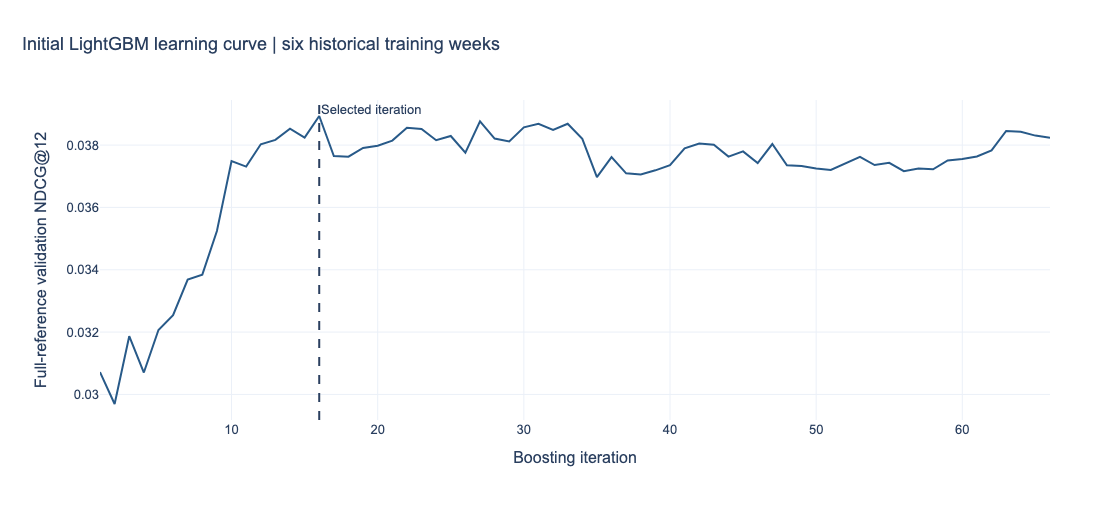

In [2]:
output=PROJECT_ROOT/'data/processed/weekly_v1/first_ranker'
learning=json.loads((output/'learning_curve.json').read_text())
values=learning['valid_0']['ndcg_full_reference_at_12']
curve=pd.DataFrame({'iteration':np.arange(1,len(values)+1),'ndcg_at_12':values})
fig=px.line(curve,x='iteration',y='ndcg_at_12',labels={'iteration':'Boosting iteration','ndcg_at_12':'Full-reference validation NDCG@12'},title='Initial LightGBM learning curve | six historical training weeks')
fig.add_vline(x=experiment['best_iteration'],line_dash='dash',annotation_text='Selected iteration')
show_figure(fig,PROJECT_ROOT,'ranker_learning_curve')

## 3. Complete-reference comparison

Every method recommends twelve distinct articles to each cohort customer. MAP, macro Recall and NDCG average equally across all target buyers. Micro Recall counts all target pairs together. Coverage and category diversity diagnose different properties and do not replace ranking quality.

,method,evaluated_customers,excluded_share_pct,target_pairs,map_at_k,recall_at_k,ndcg_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,1065,94.675,3428,0.006091,0.022700,0.012546,0.196616,0.000240,3.00000
1,preferred_product_types,1065,94.675,3428,0.005346,0.014352,0.009923,0.196616,0.017120,1.93685
2,recent_purchases_180d,1065,94.675,3428,0.025445,0.055198,0.036811,0.196616,0.334306,3.22520
3,lightgbm_initial,1065,94.675,3428,0.027023,0.056514,0.038934,0.196616,0.138497,4.44440


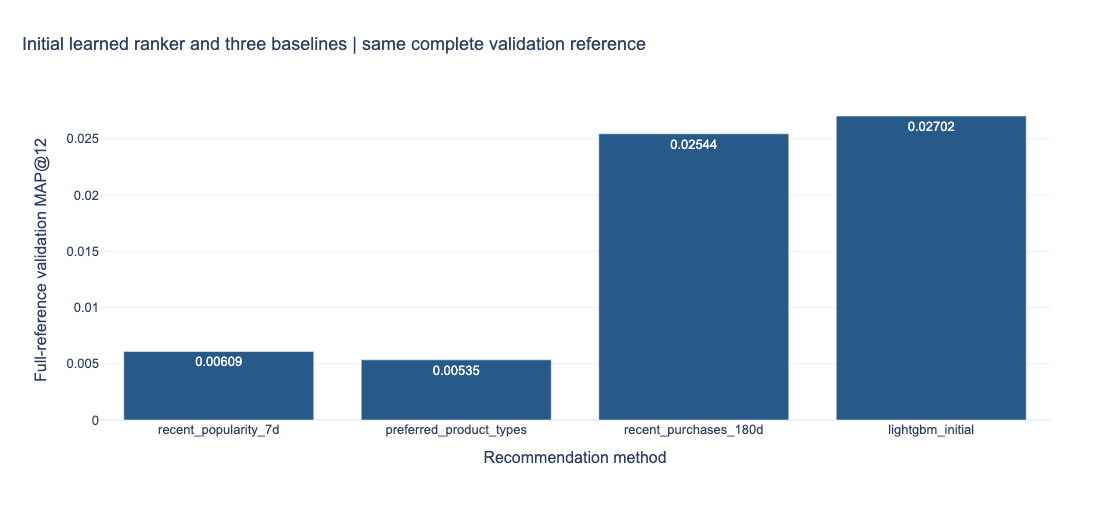

In [3]:
display(comparison[['method','evaluated_customers','excluded_share_pct','target_pairs','map_at_k','recall_at_k','ndcg_at_k','candidate_coverage','catalogue_coverage','mean_recommended_product_groups']])
fig=px.bar(comparison,x='method',y='map_at_k',text_auto='.5f',labels={'method':'Recommendation method','map_at_k':'Full-reference validation MAP@12'},title='Initial learned ranker and three baselines | same complete validation reference')
show_figure(fig,PROJECT_ROOT,'ranker_comparison')

## 4. Feature importance

Gain measures how the fitted trees used features to improve their training objective. Correlated features can substitute for one another. Importance is not a causal effect or a substitute for a controlled feature ablation.

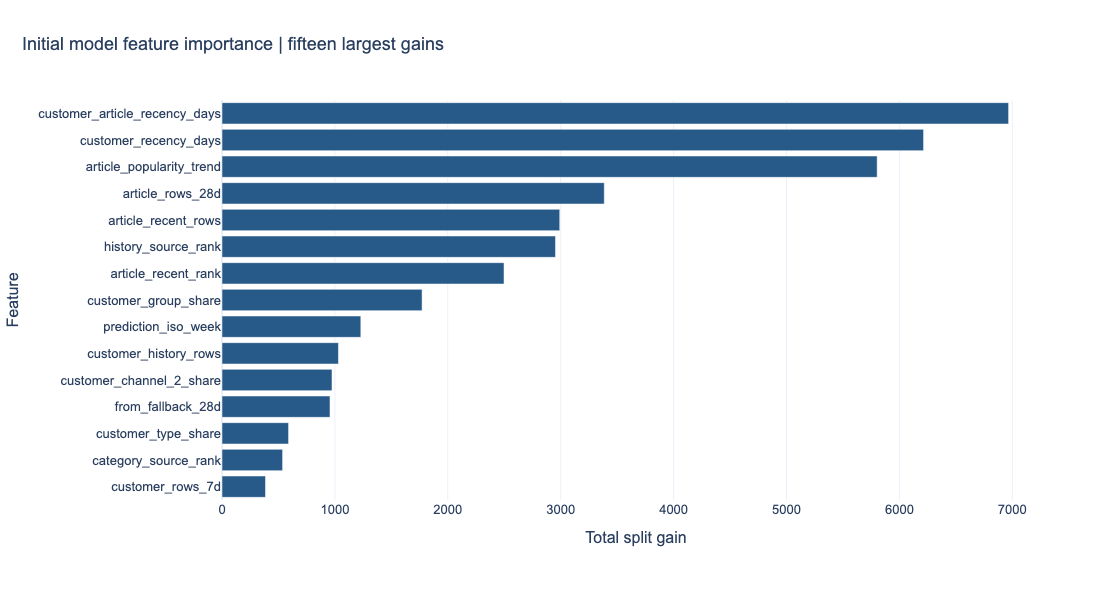

In [4]:
importance=pd.read_csv(output/'feature_importance.csv')
fig=px.bar(importance.head(15).sort_values('gain'),x='gain',y='feature',orientation='h',labels={'feature':'Feature','gain':'Total split gain'},title='Initial model feature importance | fifteen largest gains')
show_figure(fig,PROJECT_ROOT,'ranker_feature_importance',height=600)

## 5. Paired customer comparison and history segments

Compare the initial ranker with the best baseline on the same buyers. A customer-level difference is paired evidence; its sign does not establish statistical significance. Segments use only the 180-day history preceding validation, not lifetime activity.

,customers,mean_delta_ap
outcome,,
Baseline higher,38,-0.097447
Equal,966,0.000000
Model higher,61,0.088269


,history_segment,buyers,model_map,baseline_map
0,No observed history,185,0.004044,0.004979
1,1-10 rows,374,0.023117,0.024315
2,11-50 rows,435,0.037218,0.033296
3,51+ rows,71,0.045015,0.036620


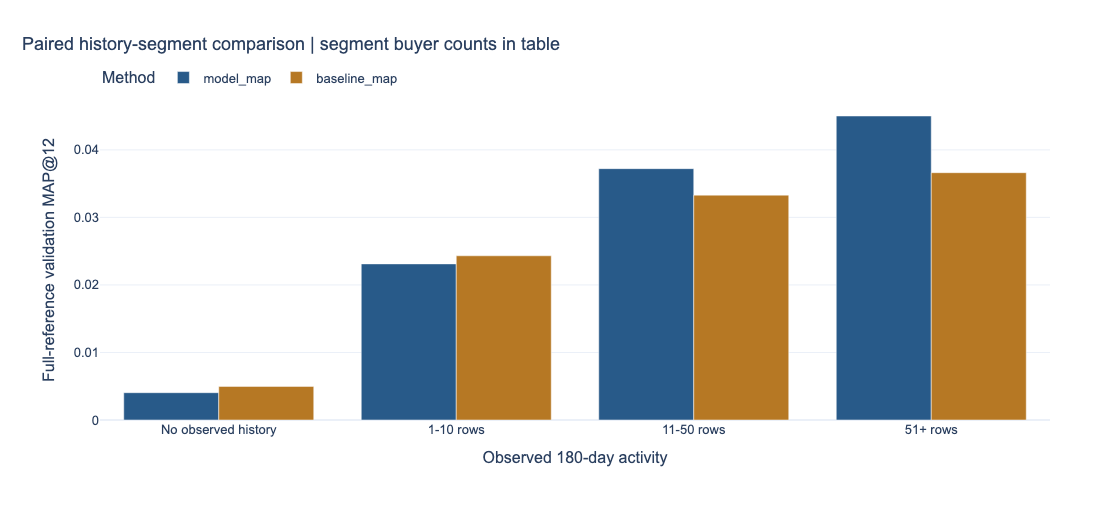

In [5]:
scores=pd.read_csv(output/'customer_scores.csv',dtype={'customer_id':'string'})
baseline= comparison.loc[comparison['method'].ne('lightgbm_initial')].sort_values(['map_at_k','method'],ascending=[False,True]).iloc[0]['method']
paired=scores.loc[scores['method'].eq('lightgbm_initial'),['customer_id','ap_at_k']].merge(scores.loc[scores['method'].eq(baseline),['customer_id','ap_at_k']],on='customer_id',validate='one_to_one',suffixes=('_model','_baseline'))
paired['delta_ap']=paired['ap_at_k_model']-paired['ap_at_k_baseline']
paired['outcome']=np.select([paired['delta_ap'].gt(0),paired['delta_ap'].lt(0)],['Model higher','Baseline higher'],default='Equal')
display(paired.groupby('outcome').agg(customers=('customer_id','size'),mean_delta_ap=('delta_ap','mean')))
from atelier_ai.workflow import cohort,build_context
ids=cohort(PROJECT_ROOT);context=build_context(PROJECT_ROOT,ids,protocol['validation_start'])
history_counts=context['history'].groupby('customer_id').size()
paired['history_rows']=paired['customer_id'].map(history_counts).fillna(0)
paired['history_segment']=pd.cut(paired['history_rows'],[-1,0,10,50,np.inf],labels=['No observed history','1-10 rows','11-50 rows','51+ rows'])
segments=paired.groupby('history_segment',observed=True).agg(buyers=('customer_id','size'),model_map=('ap_at_k_model','mean'),baseline_map=('ap_at_k_baseline','mean')).reset_index()
display(segments)
fig=px.bar(segments,x='history_segment',y=['model_map','baseline_map'],barmode='group',labels={'history_segment':'Observed 180-day activity','value':'Full-reference validation MAP@12','variable':'Method'},title='Paired history-segment comparison | segment buyer counts in table')
show_figure(fig,PROJECT_ROOT,'ranker_history_segments')
paired.to_csv(output/'paired_scores.csv',index=False);segments.to_csv(output/'history_segments.csv',index=False)

## 6. Evidence and next modelling increment

The native model is saved and reloaded; a numerical prediction check protects the round trip. Dataset/configuration/code identities, model checksum, metrics and the learning curve are recorded locally and in MLflow.

Next, compare the six planned combinations of leaves {15, 31, 63} and minimum examples {20, 100}; choose by full-reference validation MAP@12. Then complete SHAP explanations, declared ablations, uncertainty and final selection. Only after choices and iteration budgets are frozen should a selected learned model be refitted on training plus validation and evaluated on the V1 period. Final confirmation remains reserved for the frozen LightGBM/PyTorch comparison.

In [6]:
import mlflow
with mlflow.start_run(run_id=experiment['mlflow_run_id']):
    for figure_path in sorted((PROJECT_ROOT/'artifacts/figures').glob('ranker_*.png')):
        mlflow.log_artifact(str(figure_path), artifact_path='figures')
print('Saved model, metrics, provenance and figures in the local MLflow run.')

Saved model, metrics, provenance and figures in the local MLflow run.
